# Klasifikasi Topik Dokumen dengan **Naive Bayes Multinomial**


## 1. Business Understanding

**Konteks**
Sebuah platform edukasi digital dan repositori artikel teknologi ingin mengelompokkan dokumen serta deskripsi studi kasus ke dalam **6 kategori topik** secara otomatis, tanpa harus dibaca manual oleh moderator.

**Masalah**
Jumlah dokumen terus bertambah, sehingga pengecekan manual memakan waktu, tidak konsisten, dan tidak efisien.

**Data yang tersedia**
Kumpulan dokumen sudah diubah menjadi matriks **Bag-of-Words**: 600 baris (dokumen) x 334 kolom, terdiri dari 333 fitur kata dan 1 kolom `label` (kategori 1-6, masing-masing 100 dokumen).

**Tujuan**
Membangun model **Naive Bayes Multinomial** untuk memprediksi kategori topik (label 1-6) sebuah dokumen berdasarkan kata-kata yang muncul di dalamnya.

**Manfaat**
Moderasi dokumen menjadi otomatis, hemat waktu, dan konsisten.

**Batasan**
- Fitur sudah berupa angka (bukan teks mentah), sehingga tidak perlu proses vektorisasi teks.
- Sesuai ketentuan, seluruh proses dibangun **tanpa library scikit-learn** (prior, likelihood, posterior, dan evaluasi dihitung manual).

**Metrik keberhasilan**
Akurasi, dilengkapi precision, recall, dan F1-score per kelas.


## 2. Import Library

**Fungsi sel:** memuat library yang dipakai selama analisis.
- `pandas` -> membaca dan mengolah data tabular
- `numpy` -> operasi matriks (perkalian skor, log, eksponen)
- `matplotlib` & `seaborn` -> visualisasi (grafik dan heatmap)

Catatan: **tidak menggunakan scikit-learn**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 3. Dataset Understanding


### 3.1 Load Data

**Fungsi sel:** membaca file `mldataset_v1.csv` dan menampilkan dimensi serta 5 baris pertama untuk memastikan data terbaca dengan benar.


In [2]:
df = pd.read_csv('dataset/mldataset_v1.csv')

print('Jumlah baris (dokumen)     :', df.shape[0])
print('Jumlah kolom (fitur+label) :', df.shape[1])
print()
df.head()


Jumlah baris (dokumen)     : 600
Jumlah kolom (fitur+label) : 334



,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
0,1,1,1,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,1,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,1
2,1,1,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1
4,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1


### 3.2 Struktur & Statistik Deskriptif

**Fungsi sel:** melihat tipe data tiap kolom (`df.info()`), dan ringkasan statistik `min`, `max`, `mean` tiap kolom (`df.describe()`) untuk mengetahui skala nilai fitur.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Columns: 334 entries, to to label
dtypes: int64(334)
memory usage: 1.5 MB


In [4]:
df.describe()


,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
count,600.0,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,...,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.00000
mean,1.0,0.943333,0.943333,0.731667,0.660000,0.653333,0.500000,0.500000,0.480000,0.393333,...,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,3.50000
std,0.0,0.231397,0.231397,0.443462,0.474104,0.476306,0.500417,0.500417,0.500017,0.488897,...,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,1.70925
min,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00000
25%,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.00000
50%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.500000,0.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.50000
75%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.00000
max,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.00000


### 3.3 Pengecekan Missing Value

**Fungsi sel:** memastikan tidak ada nilai kosong yang bisa mengganggu proses perhitungan Naive Bayes.


In [5]:
print('Total nilai kosong (null):', df.isnull().sum().sum())


Total nilai kosong (null): 0


### 3.4 Deteksi Outlier (IQR)

**Fungsi sel:** mengecek outlier dengan metode IQR (`batas = Q1 - 1.5*IQR` dan `Q3 + 1.5*IQR`) dari dua sudut:
- **Global** -> IQR dihitung dari seluruh data.
- **Per label** -> IQR dihitung di dalam masing-masing kategori (1-6), untuk melihat apakah ada kelas dengan pola menyimpang.

**Temuan (global):** "outlier" terbanyak adalah `can`, `implement`, `how`, `classifier`, `algorithm`, `would`, dan `develop` dengan angka 150; `patterns` 110; lalu beberapa kata lain 100.

**Catatan penting:** seluruh fitur bersifat **biner (0/1)**. Pada kolom yang jarang muncul, `Q1 = Q3 = 0` sehingga `IQR = 0` dan batas atasnya juga 0, akibatnya **setiap nilai 1 selalu terbaca sebagai "outlier"** - padahal 1 berarti "kata ini ada di dokumen". Jadi angka outlier di sini sebenarnya adalah **jumlah dokumen yang memuat kata tersebut**, bukan data error.

**Kesimpulan:** **outlier tidak ditangani**, karena bukan data error maupun nilai ekstrem. Yang benar-benar ditangani pada tahap preprocessing adalah **duplikat** dan **kolom konstan**.


In [6]:
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns
fitur_outlier = [c for c in kolom_numerik if c != 'label']

# 1) Outlier global (IQR dihitung dari seluruh data)
hasil_outlier = {}
for kolom in fitur_outlier:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    hasil_outlier[kolom] = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()

hasil_outlier = pd.Series(hasil_outlier).sort_values(ascending=False)
print('10 kolom dengan outlier terbanyak (global):')
print(hasil_outlier.head(10))
print()

# 2) Outlier per label (IQR dihitung di dalam tiap kategori)
ringkasan = []
for k in sorted(df['label'].unique()):
    d = df[df['label'] == k]
    total = 0
    kolom_ber_outlier = 0
    for kolom in fitur_outlier:
        Q1 = d[kolom].quantile(0.25)
        Q3 = d[kolom].quantile(0.75)
        IQR = Q3 - Q1
        jml = int(((d[kolom] < Q1 - 1.5 * IQR) | (d[kolom] > Q3 + 1.5 * IQR)).sum())
        total += jml
        kolom_ber_outlier += 1 if jml > 0 else 0
    panjang = d[fitur_outlier].sum(axis=1).mean()
    ringkasan.append([k, total, kolom_ber_outlier, round(panjang, 2)])

ringkasan = pd.DataFrame(ringkasan, columns=['Label', 'Total_Outlier', 'Kolom_Ber_Outlier',
                                             'Rata2_Panjang_Dokumen'])
print('Outlier per label:')
print(ringkasan.to_string(index=False))
print()
print('Kesimpulan: jumlah outlier berbanding lurus dengan panjang dokumen tiap kelas.')
print('Outlier TIDAK ditangani karena semua nilai hanya 0/1 (bukan data error).')


10 kolom dengan outlier terbanyak (global):
how           150
develop       150
algorithm     150
would         150
can           150
implement     150
classifier    150
patterns      110
decision      100
knn           100
dtype: int64

Outlier per label:
 Label  Total_Outlier  Kolom_Ber_Outlier  Rata2_Panjang_Dokumen
     1            853                278                  17.18
     2            854                260                  18.21
     3            852                260                  18.20
     4            899                230                  18.61
     5            897                229                  18.62
     6            988                179                  19.10

Kesimpulan: jumlah outlier berbanding lurus dengan panjang dokumen tiap kelas.
Outlier TIDAK ditangani karena semua nilai hanya 0/1 (bukan data error).


### 3.5 Pengecekan Data Duplikat

**Fungsi sel:** menghitung jumlah baris duplikat, dan memastikan tidak ada baris dengan fitur identik tetapi label berbeda (data kontradiktif).


In [7]:
print('Jumlah baris duplikat:', df.duplicated().sum())

fitur = df.drop(columns='label')
grup = df.groupby(list(fitur.columns))['label'].nunique()
print('Kelompok fitur identik dengan label berbeda:', (grup > 1).sum())


Jumlah baris duplikat: 210
Kelompok fitur identik dengan label berbeda: 0


### 3.6 Distribusi Kelas Target

**Fungsi sel:** menghitung jumlah dokumen per kategori dan menampilkannya sebagai grafik untuk memastikan sebaran label.


label
1    100
2    100
3    100
4    100
5    100
6    100
Name: count, dtype: int64


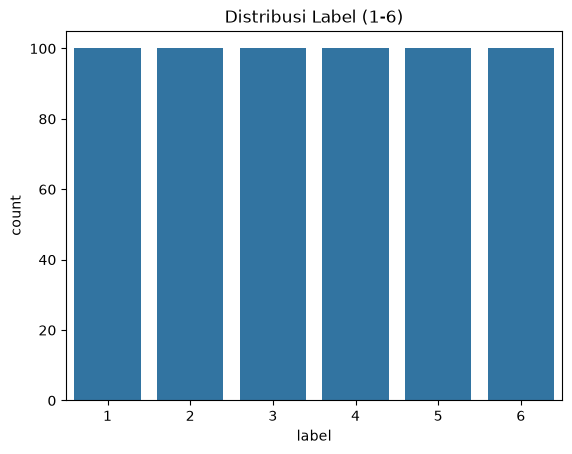

In [8]:
print(df['label'].value_counts().sort_index())

sns.countplot(x='label', data=df)
plt.title('Distribusi Label (1-6)')
plt.show()


### 3.7 Sparsity & Kolom Tidak Informatif

**Fungsi sel:** mengukur seberapa banyak sel bernilai 0, serta mendata kolom yang tidak membawa informasi (nilai konstan dan kolom yang hanya muncul di 1 dokumen).


In [9]:
fitur = df.drop(columns='label')

sparsity = (fitur == 0).sum().sum() / fitur.size * 100
print(f'Sparsity data: {sparsity:.2f}% sel bernilai 0')

kolom_konstan = [c for c in fitur.columns if fitur[c].nunique() == 1]
print('Kolom konstan (nilainya sama di semua baris):', kolom_konstan)

kolom_muncul_1x = [c for c in fitur.columns if fitur[c].sum() == 1]
print('Jumlah kolom yang hanya muncul di 1 dokumen:', len(kolom_muncul_1x))


Sparsity data: 94.50% sel bernilai 0
Kolom konstan (nilainya sama di semua baris): ['to']
Jumlah kolom yang hanya muncul di 1 dokumen: 46


### 3.8 Frekuensi Kata

**Fungsi sel:** menghitung total kemunculan setiap kata di seluruh dokumen dan menampilkan 20 kata yang paling sering muncul.


to           600
based        566
on           566
of           439
their        396
and          392
you          300
model        300
different    288
classify     236
an           214
types        203
predict      162
the          161
design       156
dtype: int64


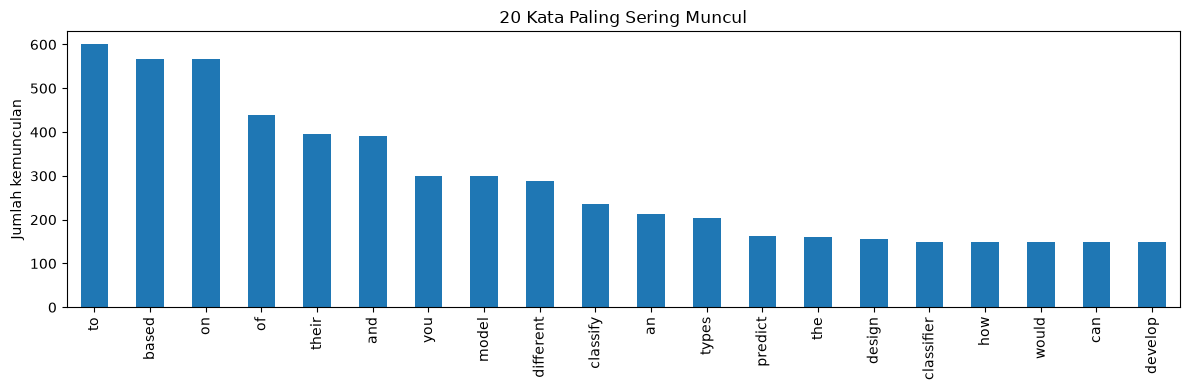

In [10]:
total_kata = fitur.sum().sort_values(ascending=False)
print(total_kata.head(15))

total_kata.head(20).plot(kind='bar', figsize=(12, 4), title='20 Kata Paling Sering Muncul')
plt.ylabel('Jumlah kemunculan')
plt.tight_layout()
plt.show()


### 3.9 Panjang Dokumen

**Fungsi sel:** menghitung jumlah kata pada tiap dokumen (jumlah nilai 1 per baris) dan melihat distribusinya.


count    600.000000
mean      18.320000
std        2.083627
min       11.000000
25%       17.000000
50%       19.000000
75%       20.000000
max       23.000000
dtype: float64


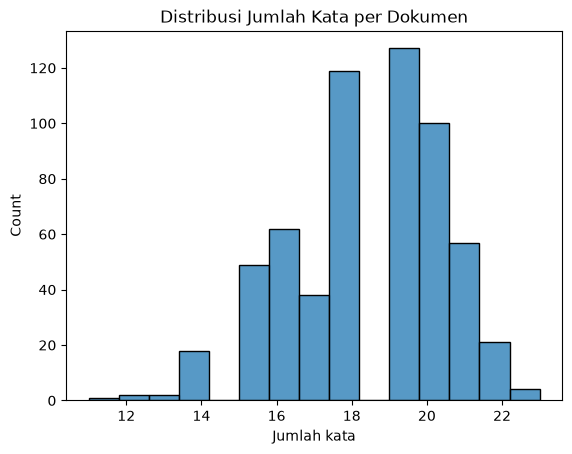

In [11]:
panjang_dokumen = fitur.sum(axis=1)
print(panjang_dokumen.describe())

sns.histplot(panjang_dokumen, bins=15)
plt.title('Distribusi Jumlah Kata per Dokumen')
plt.xlabel('Jumlah kata')
plt.show()


### 3.10 Rata-rata Kemunculan Kata per Kategori

**Fungsi sel:** menampilkan heatmap rata-rata kemunculan 10 kata terpopuler pada masing-masing kategori, untuk melihat kata mana yang menjadi penanda suatu topik.


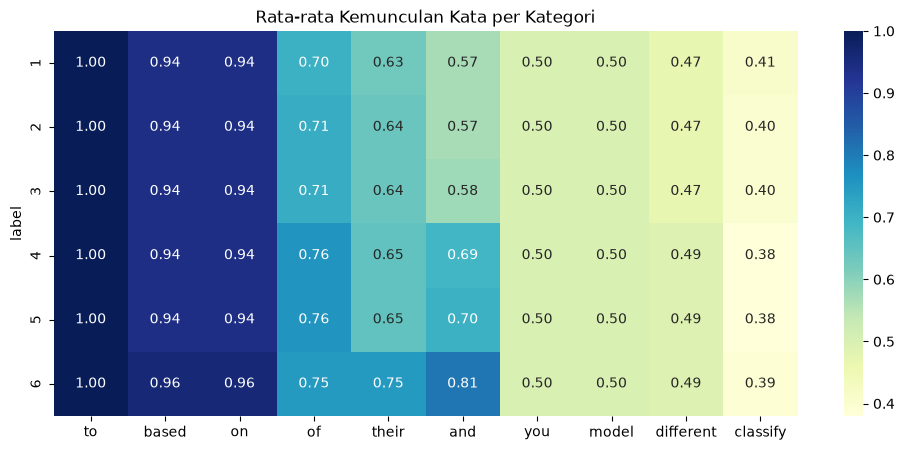

In [12]:
top10 = fitur.sum().sort_values(ascending=False).head(10).index
pivot = df.groupby('label')[top10].mean()

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Rata-rata Kemunculan Kata per Kategori')
plt.show()


## 4. Data Preprocessing


### 4.1 Menghapus Data Duplikat

**Fungsi sel:** membuang baris duplikat (`keep='first'`) agar tidak terjadi *data leakage* saat pengujian, lalu menampilkan distribusi label setelahnya.


In [13]:
print('Sebelum drop :', df.shape)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print('Sesudah drop :', df.shape)
print()
print('Distribusi label setelah drop duplikat:')
print(df['label'].value_counts().sort_index())


Sebelum drop : (600, 334)
Sesudah drop : (390, 334)

Distribusi label setelah drop duplikat:
label
1    85
2    77
3    77
4    57
5    56
6    38
Name: count, dtype: int64


### 4.2 Menghapus Kolom Konstan & Memisahkan Fitur dan Label

**Fungsi sel:** membuang kolom yang nilainya konstan (tidak membantu klasifikasi), lalu memisahkan `X` (fitur kata) dan `y` (label kategori).


In [14]:
kolom_konstan = [c for c in df.columns if df[c].nunique() == 1 and c != 'label']
df = df.drop(columns=kolom_konstan)
print('Kolom konstan yang dibuang:', kolom_konstan)

X = df.drop(columns='label')
y = df['label']

print('Bentuk X (fitur):', X.shape)
print('Bentuk y (label):', y.shape)


Kolom konstan yang dibuang: ['to']
Bentuk X (fitur): (390, 332)
Bentuk y (label): (390,)


### 4.3 Pembagian Data Latih dan Data Uji

**Fungsi sel:** membagi data 80% latih dan 20% uji secara **stratified** (proporsi tiap kelas tetap terjaga) memakai `groupby().sample()` - tanpa scikit-learn.


In [15]:
test_idx = df.groupby('label').sample(frac=0.2, random_state=42).index

X_train = X.drop(index=test_idx)
X_test  = X.loc[test_idx]
y_train = y.drop(index=test_idx)
y_test  = y.loc[test_idx]

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print()
print('Distribusi label di data uji:')
print(y_test.value_counts().sort_index())


X_train: (313, 332) | X_test: (77, 332)

Distribusi label di data uji:
label
1    17
2    15
3    15
4    11
5    11
6     8
Name: count, dtype: int64


## 5. Modeling - Naive Bayes Multinomial


### 5.1 Menghitung Prior P(k)

**Fungsi sel:** menghitung probabilitas awal setiap kelas, yaitu jumlah dokumen kelas tersebut dibagi total dokumen latih.

Rumus: `P(k) = jumlah dokumen kelas k / total dokumen`


In [16]:
kelas = sorted(y_train.unique())
prior = {}
for k in kelas:
    prior[k] = (y_train == k).sum() / y_train.shape[0]

print('Prior tiap kelas:')
for k in kelas:
    print(f'  P(kelas {k}) = {prior[k]:.4f}')


Prior tiap kelas:
  P(kelas 1) = 0.2173
  P(kelas 2) = 0.1981
  P(kelas 3) = 0.1981
  P(kelas 4) = 0.1470
  P(kelas 5) = 0.1438
  P(kelas 6) = 0.0958


### 5.2 Menghitung Likelihood P(x|k)

**Fungsi sel:** menghitung peluang kemunculan setiap kata pada tiap kelas memakai **Laplace smoothing** (alpha = 1) agar tidak ada nilai 0 yang membuat `log(0)`.

Rumus: `p_ki = (count_ki + alpha) / (count_k + alpha * jumlah_fitur)`

- `count_ki` = jumlah kemunculan kata ke-i pada kelas k
- `count_k`  = total kemunculan semua kata pada kelas k

Karena perkalian ratusan peluang sangat kecil, digunakan bentuk **log**.


In [17]:
n_fitur = X_train.shape[1]
alpha = 1.0

log_likelihood = {}
for k in kelas:
    X_kelas  = X_train[y_train == k]
    count_ki = X_kelas.sum(axis=0)
    count_k  = count_ki.sum()
    p_ki     = (count_ki + alpha) / (count_k + alpha * n_fitur)
    log_likelihood[k] = np.log(p_ki)

log_prob  = np.array([log_likelihood[k] for k in kelas])
log_prior = np.array([np.log(prior[k]) for k in kelas])

print('Bentuk matriks log-likelihood:', log_prob.shape)
print('Contoh peluang kata "bayes" pada kelas 1:',
      round(float(np.exp(log_likelihood[1]['bayes'])), 5))


Bentuk matriks log-likelihood: (6, 332)
Contoh peluang kata "bayes" pada kelas 1: 0.00071


### 5.3 Menghitung Posterior & Melakukan Prediksi

**Fungsi sel:** menghitung skor tiap kelas lalu mengubahnya menjadi posterior.

- Skor: `skor(k) = log P(k) + sum(xi * log p_ki)`
- Posterior: `P(k|x) = exp(skor(k) - log P(x))`, dengan `P(x)` dihitung memakai teknik *log-sum-exp* agar stabil.

Kelas terpilih adalah kelas dengan posterior terbesar.


In [18]:
skor_train = X_train.values @ log_prob.T + log_prior
skor_test  = X_test.values  @ log_prob.T + log_prior

# log-sum-exp untuk menghitung log P(x)
maks      = skor_test.max(axis=1, keepdims=True)
log_total = maks + np.log(np.exp(skor_test - maks).sum(axis=1, keepdims=True))

posterior_test = np.exp(skor_test - log_total)
y_pred = np.array(kelas)[skor_test.argmax(axis=1)]

hasil = pd.DataFrame(posterior_test, columns=[f'P(kelas {k})' for k in kelas], index=X_test.index)
hasil['Prediksi'] = y_pred
hasil['Aktual']   = y_test.values
print('Total probabilitas tiap baris (harus 1):', round(float(posterior_test.sum(axis=1)[0]), 6))
hasil.head()


Total probabilitas tiap baris (harus 1): 1.0


,P(kelas 1),P(kelas 2),P(kelas 3),P(kelas 4),P(kelas 5),P(kelas 6),Prediksi,Aktual
78,0.721369,0.096024,0.127511,0.002401,0.042596,0.010099,1,1
0,0.569577,0.280944,0.114407,0.004344,0.004739,0.025989,1,1
68,0.978793,0.004238,0.008806,0.005106,0.002043,0.001014,1,1
22,0.106814,0.143739,0.144301,0.423637,0.181071,0.000438,4,1
12,0.319189,0.251435,0.001297,0.407198,0.010364,0.010517,4,1


## 6. Evaluasi Model


### 6.1 Akurasi

**Fungsi sel:** menghitung persentase prediksi yang benar pada data latih dan data uji.

Rumus: `akurasi = jumlah prediksi benar / jumlah seluruh data`


In [19]:
y_pred_train = np.array(kelas)[skor_train.argmax(axis=1)]

akurasi_train = (y_pred_train == y_train.values).mean()
akurasi_test  = (y_pred == y_test.values).mean()

print(f'Akurasi data latih : {akurasi_train:.4f} ({akurasi_train * 100:.2f}%)')
print(f'Akurasi data uji   : {akurasi_test:.4f} ({akurasi_test * 100:.2f}%)')


Akurasi data latih : 1.0000 (100.00%)
Akurasi data uji   : 0.8182 (81.82%)


### 6.2 Confusion Matrix

**Fungsi sel:** menampilkan tabel silang antara kelas aktual dan kelas prediksi untuk melihat kelas mana yang sering tertukar.


Prediksi   1   2   3  4  5  6
Aktual                       
1         13   1   0  3  0  0
2          0  15   0  0  0  0
3          0   0  15  0  0  0
4          1   0   0  6  4  0
5          2   0   0  2  7  0
6          1   0   0  0  0  7


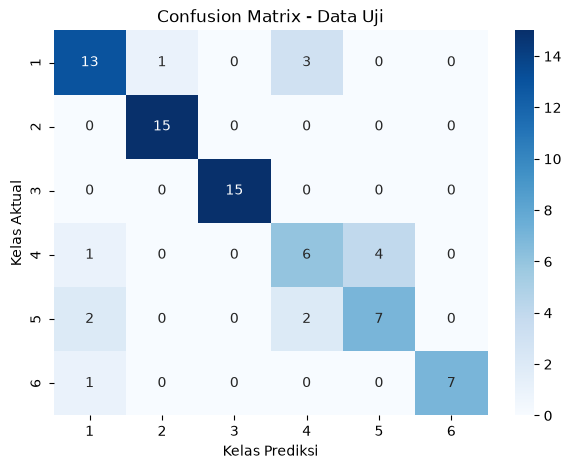

In [20]:
cm = pd.crosstab(pd.Series(y_test.values, name='Aktual'),
                 pd.Series(y_pred, name='Prediksi')).reindex(index=kelas, columns=kelas, fill_value=0)
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Data Uji')
plt.ylabel('Kelas Aktual')
plt.xlabel('Kelas Prediksi')
plt.show()


### 6.3 Precision, Recall, dan F1-Score

**Fungsi sel:** menghitung metrik evaluasi tiap kelas secara manual.

- `Precision = TP / (TP + FP)` -> dari yang diprediksi kelas k, berapa yang benar
- `Recall = TP / (TP + FN)` -> dari seluruh dokumen kelas k, berapa yang berhasil ditemukan
- `F1 = 2 * (Precision * Recall) / (Precision + Recall)`


In [21]:
laporan = []
for k in kelas:
    TP = int(((y_test == k) & (y_pred == k)).sum())
    FP = int(((y_test != k) & (y_pred == k)).sum())
    FN = int(((y_test == k) & (y_pred != k)).sum())

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    laporan.append([k, round(precision, 4), round(recall, 4), round(f1, 4), TP + FN])

laporan = pd.DataFrame(laporan, columns=['Kelas', 'Precision', 'Recall', 'F1-Score', 'Support'])
print(laporan.to_string(index=False))
print()
print(f'Rata-rata -> Precision: {laporan["Precision"].mean():.4f} | '
      f'Recall: {laporan["Recall"].mean():.4f} | F1: {laporan["F1-Score"].mean():.4f}')


 Kelas  Precision  Recall  F1-Score  Support
     1     0.7647  0.7647    0.7647       17
     2     0.9375  1.0000    0.9677       15
     3     1.0000  1.0000    1.0000       15
     4     0.5455  0.5455    0.5455       11
     5     0.6364  0.6364    0.6364       11
     6     1.0000  0.8750    0.9333        8

Rata-rata -> Precision: 0.8140 | Recall: 0.8036 | F1: 0.8079


## 7. Aplikasi Prediksi Kategori (Tkinter)

Bagian ini membuat aplikasi sederhana: pengguna mengetikkan **kata-kata** sebuah dokumen, lalu aplikasi menampilkan **dokumen tersebut masuk kategori berapa** beserta probabilitasnya.

Cara kerja: kata yang diketik diubah menjadi vektor 0/1 sesuai daftar fitur, kemudian dihitung skor dan posterior dengan model yang sudah dilatih.


### 7.1 Fungsi Prediksi

**Fungsi sel:** mengubah teks menjadi vektor fitur, menghitung posterior tiap kelas, dan mengembalikan kategori dengan probabilitas terbesar.

Catatan: kata yang tidak ada di dalam daftar fitur otomatis diabaikan.


In [22]:
def buat_vektor(teks):
    kata = set(teks.lower().split())
    return np.array([1 if kolom in kata else 0 for kolom in X_train.columns], dtype=int)


def prediksi_kategori(teks):
    vektor = buat_vektor(teks)
    skor = vektor @ log_prob.T + log_prior

    # ubah skor menjadi probabilitas (posterior)
    maks = skor.max()
    posterior = np.exp(skor - (maks + np.log(np.exp(skor - maks).sum())))

    idx = int(posterior.argmax())
    return kelas[idx], posterior


# Uji coba
contoh = 'naive bayes classifier predict model classify'
label, prob = prediksi_kategori(contoh)

print('Teks          :', contoh)
print('Hasil prediksi: kategori', label)
print()
print('Probabilitas tiap kelas:')
for k, p in zip(kelas, prob):
    print(f'  kelas {k} : {p * 100:6.2f}%')


Teks          : naive bayes classifier predict model classify
Hasil prediksi: kategori 6

Probabilitas tiap kelas:
  kelas 1 :   0.28%
  kelas 2 :   0.22%
  kelas 3 :   0.22%
  kelas 4 :   0.19%
  kelas 5 :   0.16%
  kelas 6 :  98.93%


### 7.2 Aplikasi Tkinter

**Fungsi sel:** menampilkan jendela aplikasi untuk memasukkan kata dan menampilkan hasil prediksi kategorinya.

Jalankan sel di bawah untuk membuka jendela aplikasi (jendela akan muncul terpisah dari notebook).


In [23]:
import tkinter as tk
from tkinter import messagebox


class AplikasiPrediksi(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title('Prediksi Kategori Dokumen - Naive Bayes Multinomial')
        self.geometry('640x520')
        self.configure(bg='#f0f4f8')

        header = tk.Frame(self, bg='#1f4e79', height=70)
        header.pack(fill='x')
        tk.Label(header, text='Prediksi Kategori Topik Dokumen', bg='#1f4e79', fg='white',
                 font=('Segoe UI', 14, 'bold')).pack(pady=(12, 0))
        tk.Label(header, text='Naive Bayes Multinomial', bg='#1f4e79', fg='#cfe2f3',
                 font=('Segoe UI', 10)).pack()

        body = tk.Frame(self, bg='#f0f4f8', padx=20, pady=15)
        body.pack(fill='both', expand=True)

        tk.Label(body, text='Masukkan kata-kata dokumen (pisahkan dengan spasi):',
                 bg='#f0f4f8', font=('Segoe UI', 10)).pack(anchor='w')

        self.input = tk.Text(body, height=6, font=('Segoe UI', 10), wrap='word')
        self.input.pack(fill='x', pady=(5, 10))

        tombol = tk.Frame(body, bg='#f0f4f8')
        tombol.pack(fill='x')
        tk.Button(tombol, text='Prediksi Kategori', command=self.on_prediksi,
                  bg='#1f4e79', fg='white', font=('Segoe UI', 10, 'bold'),
                  padx=12, pady=4).pack(side='left')
        tk.Button(tombol, text='Contoh', command=self.on_contoh,
                  padx=12, pady=4).pack(side='left', padx=6)
        tk.Button(tombol, text='Bersihkan', command=self.on_bersih,
                  padx=12, pady=4).pack(side='left')

        self.hasil = tk.Label(body, text='Hasil prediksi akan muncul di sini.',
                              bg='#ffffff', fg='#1f4e79', font=('Segoe UI', 11, 'bold'),
                              justify='left', anchor='w', wraplength=540,
                              padx=10, pady=10)
        self.hasil.pack(fill='x', pady=(12, 0))

        self.rincian = tk.Label(body, text='', bg='#f0f4f8', fg='#333333',
                                font=('Consolas', 9), justify='left', anchor='w')
        self.rincian.pack(fill='x', pady=(8, 0))

    def on_prediksi(self):
        teks = self.input.get('1.0', 'end').strip()
        if not teks:
            messagebox.showwarning('Peringatan', 'Silakan masukkan kata terlebih dahulu.')
            return

        if buat_vektor(teks).sum() == 0:
            messagebox.showwarning('Peringatan',
                                   'Tidak ada kata yang dikenali model.\nCoba kata lain.')
            return

        label, prob = prediksi_kategori(teks)
        urut = np.argsort(prob)[::-1]

        self.hasil.config(text=f'Dokumen ini masuk ke KATEGORI {label}')
        baris = '\n'.join(f'  kelas {kelas[i]} : {prob[i] * 100:6.2f}%' for i in urut)
        self.rincian.config(text='Probabilitas tiap kelas:\n' + baris)

    def on_contoh(self):
        self.input.delete('1.0', 'end')
        self.input.insert('1.0', 'naive bayes classifier predict model classify')

    def on_bersih(self):
        self.input.delete('1.0', 'end')
        self.hasil.config(text='Hasil prediksi akan muncul di sini.')
        self.rincian.config(text='')


app = AplikasiPrediksi()
app.mainloop()


## 8. Kesimpulan


### 8.1 Kesimpulan Tahap Dataset

- Dataset berisi **600 dokumen x 334 kolom** (333 fitur kata + 1 kolom `label`), seluruhnya bertipe `int64`.
- **Tidak ada nilai kosong**, dan label **seimbang**: 100 dokumen per kategori (kelas 1-6).
- Ditemukan **210 baris duplikat**, namun **tidak ada** data kontradiktif (fitur sama dengan label berbeda).
- Data sangat **sparse**: **94,50%** sel bernilai 0 - ciri khas representasi Bag-of-Words.
- Terdapat **1 kolom konstan** (`to`, selalu bernilai 1) dan **46 kolom** yang hanya muncul di 1 dokumen.
- Kata paling sering muncul: `to` (600), `on` dan `based` (566).
- Panjang dokumen **11-23 kata**, rata-rata **18,32 kata** per dokumen.
- Fitur bersifat **biner (0/1)** dan sudah berbentuk Bag-of-Words, sehingga tidak perlu vektorisasi teks.
- Pengecekan outlier (IQR) - baik global maupun per label - hanya mencerminkan **jumlah dokumen yang memuat tiap kata** (karena semua fitur bernilai biner dan `IQR = 0`), sehingga **outlier tidak ditangani**; jumlahnya berbanding lurus dengan panjang dokumen tiap kelas.


### 8.2 Kesimpulan Tahap Preprocessing

- **210 baris duplikat dihapus** sehingga data menjadi **390 baris** - mencegah model "menghafal" data uji.
- Kolom konstan **`to` dibuang**, sehingga jumlah fitur menjadi **332**.
- Setelah duplikat dibuang, kelas menjadi **tidak seimbang**: 85, 77, 77, 57, 56, dan 38 dokumen (kelas 6 paling sedikit) karena duplikat paling banyak menumpuk di kelas 6.
- Data dibagi **stratified 80:20** menjadi **313 data latih** dan **77 data uji**, dengan proporsi kelas tetap terjaga.


### 8.3 Kesimpulan Tahap Modeling

- Model Naive Bayes Multinomial dibangun **manual tanpa scikit-learn**, melalui 3 tahap: **prior**, **likelihood** (Laplace smoothing alpha = 1), dan **posterior**.
- Prior tertinggi ada di **kelas 1 (0,2173)** dan terendah di **kelas 6 (0,0958)**, akibat ketidakseimbangan setelah duplikat dibuang.
- Matriks log-likelihood berukuran **6 x 332** (6 kelas x 332 fitur).
- Klasifikasi dilakukan dengan mengambil **nilai posterior terbesar**; hasil penjumlahan posterior tiap dokumen terbukti = 1.


### 8.4 Kesimpulan Tahap Evaluasi

- Akurasi data latih **100%**, sedangkan akurasi data uji **81,82%** (63 dari 77 dokumen benar).
- Rata-rata **precision 81,40%**, **recall 80,36%**, dan **F1-score 80,79%**.
- Kinerja terbaik pada **kelas 3** (F1 = 1,00) dan **kelas 2** (F1 = 0,97).
- Kinerja terlemah pada **kelas 4** (F1 = 0,55) dan **kelas 5** (F1 = 0,64) - keduanya sering tertukar: 4 dokumen kelas 4 diprediksi sebagai kelas 5, dan 2 dokumen kelas 5 diprediksi sebagai kelas 4.
- Kelas 6 memiliki recall 0,875 karena 1 dokumennya terprediksi sebagai kelas 1.


### 8.5 Kesimpulan Akhir

1. **Dataset**: 600 dokumen x 334 kolom (333 fitur kata biner + 1 label), tanpa nilai kosong, tetapi mengandung 210 duplikat dan sangat sparse (94,50% sel bernilai 0).
2. **Preprocessing**: duplikat dihapus (390 baris), kolom konstan dibuang (332 fitur), lalu dibagi stratified 80:20 menjadi 313 data latih dan 77 data uji.
3. **Modeling**: model Naive Bayes Multinomial dibangun manual tanpa scikit-learn menggunakan prior, likelihood dengan Laplace smoothing, dan posterior.
4. **Evaluasi**: model mencapai akurasi **81,82%** pada data uji dengan rata-rata F1-score **80,79%**, sehingga cukup baik untuk mengelompokkan dokumen ke 6 kategori topik secara otomatis.
5. **Aplikasi**: model diterapkan pada aplikasi Tkinter yang dapat menerima masukan kata dan langsung menampilkan kategori dokumennya.
6. **Keterbatasan & saran**: jumlah data unik relatif sedikit dan tidak seimbang, serta ada 46 fitur yang hanya muncul di 1 dokumen. Perbaikan yang bisa dilakukan: membuang fitur yang sangat jarang, menangani ketidakseimbangan kelas, mencoba nilai `alpha` lain, atau menambah jumlah data.
